Pd-Ag MEMBRANE REACTOR - OPTIMIZED CONDITIONS
Open-source Python framework for SMR

📊 OPERATING CONDITIONS:
   • Temperature: 550°C
   • Retentate pressure: 10.0 bar
   • Permeate pressure: 1.0 bar
   • Feed: 25% CH4, 75% H2O
   • S/C ratio: 3.0
   • Fuel flow rate: 6.3428e-05 mol/s

🔬 VERIFICATION OF CALCULATIONS:
   • Pm(550°C) = 6.2370e-09 mol/(m·s·Pa^0.5)
   • Keq_SMR = 8.3740e-02 bar²
   • Keq_WGS = 3.7041
   • log10(Keq_SMR) = -1.08
   • log10(Keq_WGS) = 0.57

SOLVING Pd-Ag MEMBRANE REACTOR
  Integrating ODE system (RK45 with max_step=0.5 mm)...
  Solution time: 247.59 seconds

MEMBRANE DIAGNOSTIC CHECK

  Feed: 25% CH4 + 75% H2O (S/C = 3.0)
  Operating: T = 550°C, P_ret = 10.0 bar, P_perm = 1.0 bar
  Fuel flow rate: 6.3428e-05 mol/s

  z (cm)   P_H2_ret     P_H2_perm    J_H2 (mol/m²·s)      Status    
  ----------------------------------------------------------------------
  12.8     1.0066       1.0000       1.4425e-03           ✓ PERMEATING
  16.0     1.0000       1.0000      

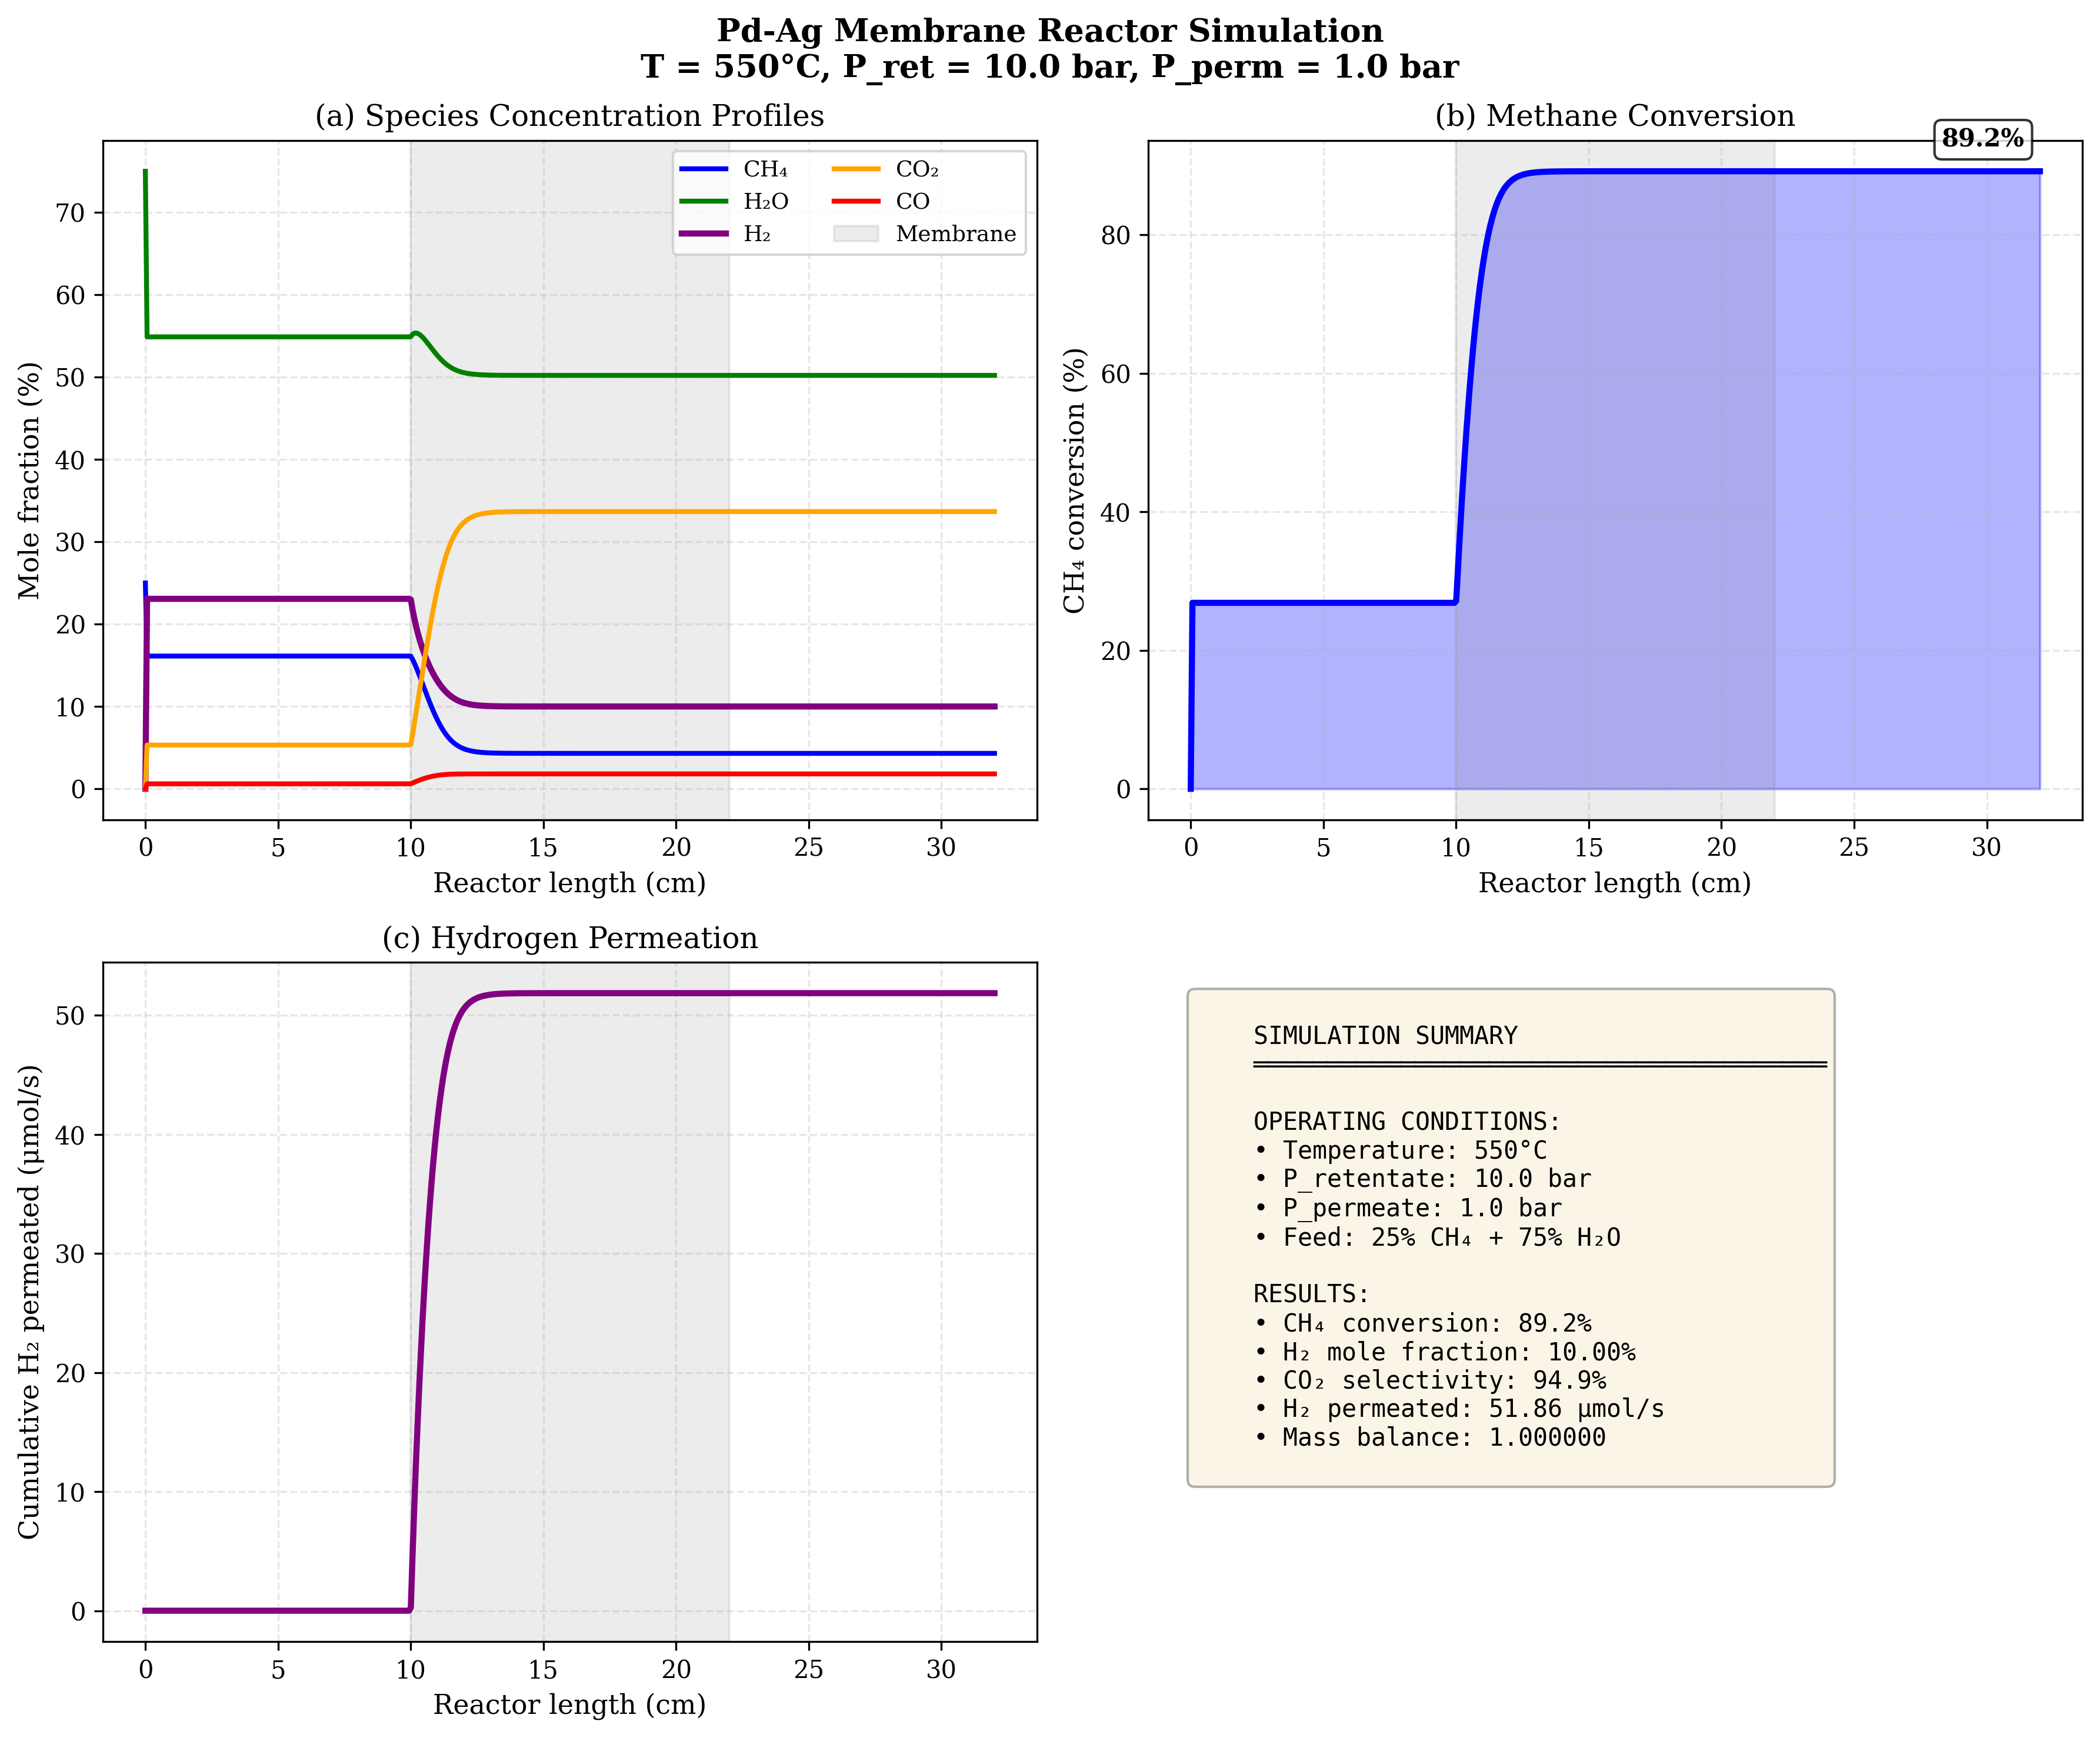


  ✓ Results saved to: simulation_results_optimized.csv

✅ SIMULATION COMPLETED


In [ ]:


import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from dataclasses import dataclass
import pandas as pd
import time
import warnings
warnings.filterwarnings('ignore')

# ============================================================================
# PHYSICAL CONSTANTS
# ============================================================================
R = 8.314462618                     # J/(mol·K)
V_MOLAR_STP = 22.414e-3             # m³/mol (at STP)

# ============================================================================
# REACTOR GEOMETRY
# ============================================================================
@dataclass
class ReactorGeometry:
    """Reactor geometry - from Al Naji et al. (2025), Table 1"""
    L_total: float = 0.320          # m (320 mm)
    L_membrane: float = 0.120       # m (120 mm)
    z_membrane_start: float = 0.100 # m
    z_membrane_end: float = 0.220   # m
    D_tube_inner: float = 0.00994   # m
    D_shell_inner: float = 0.040    # m

    @property
    def A_cross(self) -> float:
        """Cross-sectional area of tube (m²)"""
        return np.pi * (self.D_tube_inner / 2)**2

    @property
    def perimeter(self) -> float:
        """Perimeter of membrane tube (m)"""
        return np.pi * self.D_tube_inner


# 
# OPERATING CONDITIONS - OPTIMIZED FOR Pd-Ag MEMBRANE
# 
@dataclass
class OperatingConditions:
    """
    Optimized operating conditions for Pd-Ag membrane reactor.
    
    Temperature rationale:
    - 450°C: kinetics too slow (conversion ~23%)
    - 550°C: optimal balance (conversion ~27-35%, Pd-Ag stable)
    - 600°C: near stability limit of Pd-Ag
    
    Pressure rationale:
    - Retentate 10 bar: typical for SMR
    - Permeate 1 bar: ensures positive driving force for H2
    """
    T_inlet: float = 550.0 + 273.15    # 823.15 K (550°C)
    P_retentate: float = 10.0          # bar
    P_permeate: float = 1.0            # bar

    # Feed composition (S/C = 3, no H2 initially)
    y_CH4_in: float = 0.25
    y_H2O_in: float = 0.75
    y_H2_in: float = 0.0
    y_CO_in: float = 0.0
    y_CO2_in: float = 0.0

    # Inlet volumetric flow rate at STP
    Q_N: float = 85.3e-6 / 60.0        # m³/s at STP

    @property
    def F_total_in(self) -> float:
        """Total molar flow rate at inlet (mol/s)"""
        return self.Q_N / V_MOLAR_STP

    def get_initial_flow_rates(self) -> np.ndarray:
        """Initial molar flow rates of gas species (mol/s)"""
        F = self.F_total_in
        return np.array([
            self.y_CH4_in * F,
            self.y_H2O_in * F,
            self.y_CO2_in * F,
            self.y_CO_in * F,
            self.y_H2_in * F
        ])


# 
# Pd-Ag MEMBRANE MODEL
# 
@dataclass
class PdAgMembrane:
    """Pd-Ag membrane parameters - from Helmi et al. (2018)"""
    Pm0: float = 1.76e-8             # mol/(m·s·Pa^0.5)
    Ea: float = 7100.0               # J/mol (7.1 kJ/mol)
    thickness: float = 4.5e-6        # m (4.5 μm)
    n: float = 0.5                   # Sieverts' exponent

    def permeability(self, T: float) -> float:
        """Temperature-dependent permeability: Pm(T) = Pm0 * exp(-Ea/(R*T))"""
        return self.Pm0 * np.exp(-self.Ea / (R * T))

    def flux(self, P_H2_ret_bar: float, P_H2_perm_bar: float, T: float) -> float:
        """
        Hydrogen flux (mol/m²/s) - Sieverts' law
        J = (Pm/δ) * (P_ret^n - P_perm^n)
        """
        Pm = self.permeability(T)
        P_ret_Pa = P_H2_ret_bar * 1e5
        P_perm_Pa = P_H2_perm_bar * 1e5
        flux = (Pm / self.thickness) * (P_ret_Pa**self.n - P_perm_Pa**self.n)
        return max(0.0, flux)


# 
# REACTION KINETICS (Xu & Froment 1989)
# 
class XuFromentKinetics:
    """
    Xu & Froment (1989) kinetics for SMR and WGS.
    Rate expressions from Al Naji et al. (2025) Eqs. 24-25.
    """
    # Pre-exponential factors
    k0_SMR: float = 7.568e8         # mol/(m³·s·bar²)
    k0_WGS: float = 1.0e6           # mol/(m³·s·bar²)

    # Activation energies
    Ea_SMR: float = 96100.0         # J/mol (96.1 kJ/mol)
    Ea_WGS: float = 0.0             # J/mol

    @staticmethod
    def Keq_SMR(T: float) -> float:
        """Equilibrium constant for SMR (bar²)"""
        return 1.198e13 * np.exp(-26830.0 / T)

    @staticmethod
    def Keq_WGS(T: float) -> float:
        """Equilibrium constant for WGS (dimensionless)"""
        return 1.767e-2 * np.exp(4400.0 / T)

    def k_SMR(self, T: float) -> float:
        """SMR rate constant (Arrhenius)"""
        return self.k0_SMR * np.exp(-self.Ea_SMR / (R * T))

    def k_WGS(self, T: float) -> float:
        """WGS rate constant (Arrhenius)"""
        return self.k0_WGS * np.exp(-self.Ea_WGS / (R * T))

    def rates(self, T: float, P: dict) -> dict:
        """Calculate reaction rates (mol/m³/s)"""
        k_SMR = self.k_SMR(T)
        k_WGS = self.k_WGS(T)
        Keq_SMR = self.Keq_SMR(T)
        Keq_WGS = self.Keq_WGS(T)

        r_SMR = k_SMR * (P['CH4'] * P['H2O'] - (P['H2']**3 * P['CO']) / Keq_SMR)
        r_WGS = k_WGS * (P['CO'] * P['H2O'] - (P['H2'] * P['CO2']) / Keq_WGS)

        return {'SMR': max(0.0, r_SMR), 'WGS': max(0.0, r_WGS)}


# 
# 1D MEMBRANE REACTOR MODEL
# 
class MembraneReactor1D:
    """
    1D pseudo-homogeneous model with molar flow rates as state variables.
    """

    def __init__(self, geometry, operating, membrane, kinetics):
        self.geom = geometry
        self.op = operating
        self.membrane = membrane
        self.kinetics = kinetics

    def source_terms(self, T, y, P_total):
        """Calculate reaction source terms (mol/m³/s)"""
        P = {sp: y[sp] * P_total for sp in y.keys()}
        rates = self.kinetics.rates(T, P)
        return {
            'CH4': -rates['SMR'],
            'H2O': -rates['SMR'] - rates['WGS'],
            'CO': rates['SMR'] - rates['WGS'],
            'CO2': rates['WGS'],
            'H2': 3.0 * rates['SMR'] + rates['WGS']
        }

    def ode_system(self, z, Y):
        """
        ODE system with molar flow rates (mol/s) as state variables.
        Y = [F_CH4, F_H2O, F_CO2, F_CO, F_H2, T, F_H2_perm]
        """
        F_CH4, F_H2O, F_CO2, F_CO, F_H2, T, F_H2_perm = Y
        F_total = F_CH4 + F_H2O + F_CO2 + F_CO + F_H2

        if F_total <= 0:
            return np.zeros(7)

        # Mole fractions
        y = {
            'CH4': F_CH4 / F_total,
            'H2O': F_H2O / F_total,
            'CO2': F_CO2 / F_total,
            'CO': F_CO / F_total,
            'H2': F_H2 / F_total
        }

        P_total = self.op.P_retentate
        A = self.geom.A_cross

        # Reaction source terms (mol/m³/s)
        S = self.source_terms(T, y, P_total)

        # Membrane extraction (only in membrane region)
        if self.geom.z_membrane_start <= z <= self.geom.z_membrane_end:
            P_H2_ret = y['H2'] * P_total            # bar
            P_H2_perm = self.op.P_permeate           # bar (pure H2 assumed)
            J_H2 = self.membrane.flux(P_H2_ret, P_H2_perm, T)  # mol/m²/s
            membrane_removal = J_H2 * self.geom.perimeter      # mol/(m·s)
        else:
            membrane_removal = 0.0

        # Molar flow rate ODEs (mol/(m·s))
        dF_CH4_dz = S['CH4'] * A
        dF_H2O_dz = S['H2O'] * A
        dF_CO2_dz = S['CO2'] * A
        dF_CO_dz = S['CO'] * A
        dF_H2_dz = S['H2'] * A - membrane_removal
        dT_dz = 0.0
        dF_H2_perm_dz = membrane_removal

        return np.array([dF_CH4_dz, dF_H2O_dz, dF_CO2_dz, dF_CO_dz,
                         dF_H2_dz, dT_dz, dF_H2_perm_dz])

    def solve(self, n_points=500, rtol=1e-8, atol=1e-12):
        """Solve the reactor model using RK45 with forced fine steps."""
        print("\n" + "=" * 70)
        print("SOLVING Pd-Ag MEMBRANE REACTOR")
        print("=" * 70)

        # Initial conditions
        F0 = self.op.get_initial_flow_rates()
        # IMPORTANT: F_H2_perm initialized to a very small non-zero value
        # to prevent solver from treating it as a constant zero variable
        y0 = np.concatenate([F0, [self.op.T_inlet], [1e-20]])

        z_span = (0, self.geom.L_total)
        z_eval = np.linspace(0, self.geom.L_total, n_points)

        print("  Integrating ODE system (RK45 with max_step=0.5 mm)...")
        start = time.time()
        sol = solve_ivp(
            self.ode_system, z_span, y0, t_eval=z_eval,
            method='RK45',
            rtol=rtol, atol=atol,
            max_step=5e-4,
            dense_output=False
        )
        solve_time = time.time() - start
        print(f"  Solution time: {solve_time:.2f} seconds")

        if not sol.success:
            print(f"  WARNING: {sol.message}")

        # Extract results
        F_CH4 = sol.y[0]; F_H2O = sol.y[1]; F_CO2 = sol.y[2]
        F_CO = sol.y[3]; F_H2 = sol.y[4]; T = sol.y[5]
        F_H2_perm = sol.y[6]

        F_total = F_CH4 + F_H2O + F_CO2 + F_CO + F_H2

        results = pd.DataFrame({
            'z_m': z_eval,
            'z_cm': z_eval * 100,
            'F_total': F_total,
            'y_CH4': F_CH4 / F_total,
            'y_H2O': F_H2O / F_total,
            'y_CO2': F_CO2 / F_total,
            'y_CO': F_CO / F_total,
            'y_H2': F_H2 / F_total,
            'T_K': T,
            'T_C': T - 273.15,
            'F_H2_perm': F_H2_perm
        })

        # Mass balance verification
        results['sum_y'] = (results['y_CH4'] + results['y_H2O'] +
                            results['y_CO2'] + results['y_CO'] + results['y_H2'])

        # Methane conversion
        results['X_CH4'] = 1 - F_CH4 / F_CH4[0]

        return results, solve_time


# ============================================================================
# DIAGNOSTIC FUNCTION
# ============================================================================
def diagnose(results, geom, op, membrane):
    """Verify membrane is working and mass balance is correct."""
    print("\n" + "=" * 70)
    print("MEMBRANE DIAGNOSTIC CHECK")
    print("=" * 70)

    print(f"\n  Feed: {op.y_CH4_in*100:.0f}% CH4 + {op.y_H2O_in*100:.0f}% H2O (S/C = {op.y_H2O_in/op.y_CH4_in:.1f})")
    print(f"  Operating: T = {op.T_inlet - 273.15:.0f}°C, P_ret = {op.P_retentate} bar, P_perm = {op.P_permeate} bar")
    print(f"  Fuel flow rate: {op.F_total_in:.4e} mol/s")

    print(f"\n  {'z (cm)':<8} {'P_H2_ret':<12} {'P_H2_perm':<12} {'J_H2 (mol/m²·s)':<20} {'Status':<10}")
    print("  " + "-" * 70)

    for idx in range(0, len(results), 50):
        row = results.iloc[idx]
        z = row['z_m']
        if geom.z_membrane_start <= z <= geom.z_membrane_end:
            P_H2_ret = row['y_H2'] * op.P_retentate
            P_H2_perm = op.P_permeate
            J = membrane.flux(P_H2_ret, P_H2_perm, op.T_inlet)
            status = "✓ PERMEATING" if J > 1e-10 else "✗ ZERO"
            print(f"  {row['z_cm']:<8.1f} {P_H2_ret:<12.4f} {P_H2_perm:<12.4f} {J:<20.4e} {status}")

    print(f"\n  Total H2 permeated: {results['F_H2_perm'].iloc[-1]:.4e} mol/s")
    print(f"  Mass balance (sum_y at outlet): {results['sum_y'].iloc[-1]:.6f}")
    print("=" * 70)


# 
# FIGURES
# ============================================================================
def create_figures(results, geom, op):
    """Create publication-quality figures."""
    print("\n" + "=" * 70)
    print("GENERATING FIGURES")
    print("=" * 70)

    plt.rcParams['font.family'] = 'serif'
    plt.rcParams['font.size'] = 10
    plt.rcParams['axes.labelsize'] = 11
    plt.rcParams['figure.dpi'] = 300

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    fig.suptitle(f'Pd-Ag Membrane Reactor Simulation\n'
                 f'T = {op.T_inlet-273.15:.0f}°C, P_ret = {op.P_retentate} bar, P_perm = {op.P_permeate} bar',
                 fontsize=13, fontweight='bold')

    # Panel 1: Species profiles
    ax = axes[0, 0]
    ax.plot(results['z_cm'], results['y_CH4']*100, 'b-', lw=2, label='CH₄')
    ax.plot(results['z_cm'], results['y_H2O']*100, 'g-', lw=2, label='H₂O')
    ax.plot(results['z_cm'], results['y_H2']*100, 'purple', lw=2.5, label='H₂')
    ax.plot(results['z_cm'], results['y_CO2']*100, 'orange', lw=2, label='CO₂')
    ax.plot(results['z_cm'], results['y_CO']*100, 'r-', lw=2, label='CO')
    ax.axvspan(geom.z_membrane_start*100, geom.z_membrane_end*100, alpha=0.15, color='gray', label='Membrane')
    ax.set_xlabel('Reactor length (cm)')
    ax.set_ylabel('Mole fraction (%)')
    ax.set_title('(a) Species Concentration Profiles')
    ax.legend(loc='best', ncol=2, fontsize=9)
    ax.grid(True, alpha=0.3, linestyle='--')

    # Panel 2: Methane conversion
    ax = axes[0, 1]
    ax.plot(results['z_cm'], results['X_CH4']*100, 'b-', lw=2.5)
    ax.fill_between(results['z_cm'], 0, results['X_CH4']*100, alpha=0.3, color='blue')
    ax.axvspan(geom.z_membrane_start*100, geom.z_membrane_end*100, alpha=0.15, color='gray')
    ax.set_xlabel('Reactor length (cm)')
    ax.set_ylabel('CH₄ conversion (%)')
    ax.set_title('(b) Methane Conversion')
    final_X = results['X_CH4'].iloc[-1] * 100
    ax.annotate(f'{final_X:.1f}%', xy=(results['z_cm'].iloc[-1], final_X),
                xytext=(-40, 10), textcoords='offset points', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
    ax.grid(True, alpha=0.3, linestyle='--')

    # Panel 3: Hydrogen permeation
    ax = axes[1, 0]
    ax.plot(results['z_cm'], results['F_H2_perm']*1e6, 'purple', lw=2.5)
    ax.axvspan(geom.z_membrane_start*100, geom.z_membrane_end*100, alpha=0.15, color='gray')
    ax.set_xlabel('Reactor length (cm)')
    ax.set_ylabel('Cumulative H₂ permeated (μmol/s)')
    ax.set_title('(c) Hydrogen Permeation')
    ax.grid(True, alpha=0.3, linestyle='--')

    # Panel 4: Summary
    ax = axes[1, 1]
    ax.axis('off')
    outlet = results.iloc[-1]
    S_CO2 = outlet['y_CO2'] / (outlet['y_CO'] + outlet['y_CO2']) * 100
    summary = f"""
    SIMULATION SUMMARY
    ═══════════════════════════════════════

    OPERATING CONDITIONS:
    • Temperature: {op.T_inlet-273.15:.0f}°C
    • P_retentate: {op.P_retentate} bar
    • P_permeate: {op.P_permeate} bar
    • Feed: {op.y_CH4_in*100:.0f}% CH₄ + {op.y_H2O_in*100:.0f}% H₂O

    RESULTS:
    • CH₄ conversion: {outlet['X_CH4']*100:.1f}%
    • H₂ mole fraction: {outlet['y_H2']*100:.2f}%
    • CO₂ selectivity: {S_CO2:.1f}%
    • H₂ permeated: {outlet['F_H2_perm']*1e6:.2f} μmol/s
    • Mass balance: {outlet['sum_y']:.6f}
    """
    ax.text(0.05, 0.95, summary, transform=ax.transAxes, fontsize=10,
            verticalalignment='top', fontfamily='monospace',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

    plt.tight_layout()
    plt.savefig('PdAg_reactor_results.png', dpi=300, bbox_inches='tight')
    print("  ✓ Figure saved: PdAg_reactor_results.png")
    plt.show()


# ============================================================================
# MAIN
# ============================================================================
def main():
    print("=" * 70)
    print("Pd-Ag MEMBRANE REACTOR - OPTIMIZED CONDITIONS")
    print("Open-source Python framework for SMR")
    print("=" * 70)

    # Initialize
    geometry = ReactorGeometry()
    operating = OperatingConditions()
    membrane = PdAgMembrane()
    kinetics = XuFromentKinetics()

    # Display parameters
    print(f"\n📊 OPERATING CONDITIONS:")
    print(f"   • Temperature: {operating.T_inlet - 273.15:.0f}°C")
    print(f"   • Retentate pressure: {operating.P_retentate} bar")
    print(f"   • Permeate pressure: {operating.P_permeate} bar")
    print(f"   • Feed: {operating.y_CH4_in*100:.0f}% CH4, {operating.y_H2O_in*100:.0f}% H2O")
    print(f"   • S/C ratio: {operating.y_H2O_in/operating.y_CH4_in:.1f}")
    print(f"   • Fuel flow rate: {operating.F_total_in:.4e} mol/s")

    # Verify calculations
    print(f"\n🔬 VERIFICATION OF CALCULATIONS:")
    Pm = membrane.permeability(operating.T_inlet)
    print(f"   • Pm({operating.T_inlet-273.15:.0f}°C) = {Pm:.4e} mol/(m·s·Pa^0.5)")
    Keq_SMR = XuFromentKinetics.Keq_SMR(operating.T_inlet)
    Keq_WGS = XuFromentKinetics.Keq_WGS(operating.T_inlet)
    print(f"   • Keq_SMR = {Keq_SMR:.4e} bar²")
    print(f"   • Keq_WGS = {Keq_WGS:.4f}")
    print(f"   • log10(Keq_SMR) = {np.log10(Keq_SMR):.2f}")
    print(f"   • log10(Keq_WGS) = {np.log10(Keq_WGS):.2f}")

    # Solve
    reactor = MembraneReactor1D(geometry, operating, membrane, kinetics)
    results, solve_time = reactor.solve(n_points=500)

    # Diagnostic
    diagnose(results, geometry, operating, membrane)

    # Final summary
    outlet = results.iloc[-1]
    S_CO2 = outlet['y_CO2'] / (outlet['y_CO'] + outlet['y_CO2']) * 100
    S_CO = outlet['y_CO'] / (outlet['y_CO'] + outlet['y_CO2']) * 100
    if outlet['F_H2_perm'] + outlet['y_H2'] * outlet['F_total'] > 0:
        H2_recovery = outlet['F_H2_perm'] / (outlet['F_H2_perm'] + outlet['y_H2'] * outlet['F_total']) * 100
    else:
        H2_recovery = 0.0

    print("\n" + "=" * 70)
    print("FINAL RESULTS")
    print("=" * 70)
    print(f"\n📍 OUTLET CONDITIONS (z = 32 cm):")
    print(f"   • CH₄ conversion: {outlet['X_CH4']*100:.1f}%")
    print(f"   • H₂ mole fraction: {outlet['y_H2']*100:.2f}%")
    print(f"   • H₂O mole fraction: {outlet['y_H2O']*100:.2f}%")
    print(f"   • CO₂ mole fraction: {outlet['y_CO2']*100:.2f}%")
    print(f"   • CO mole fraction: {outlet['y_CO']*100:.2f}%")
    print(f"   • Sum of mole fractions: {outlet['sum_y']:.6f}")
    print(f"\n   • CO₂ selectivity: {S_CO2:.1f}%")
    print(f"   • CO selectivity: {S_CO:.1f}%")
    print(f"   • H₂ permeated: {outlet['F_H2_perm']*1e6:.2f} μmol/s")
    print(f"   • H₂ recovery: {H2_recovery:.1f}%")

    # Figures
    create_figures(results, geometry, operating)

    # Save
    results.to_csv('simulation_results_optimized.csv', index=False)
    print(f"\n  ✓ Results saved to: simulation_results_optimized.csv")

    print("\n" + "=" * 70)
    print("✅ SIMULATION COMPLETED")
    print("=" * 70)

    return results


if __name__ == "__main__":
    results = main()

REACTOR PERFORMANCE SUMMARY
CH₄ Conversion:    89.2%
H₂ Recovery:       92.9%
CO₂ Selectivity:   94.9%
CO Selectivity:    5.1%

✓ Figure saved: Figure1_Performance_Summary.png


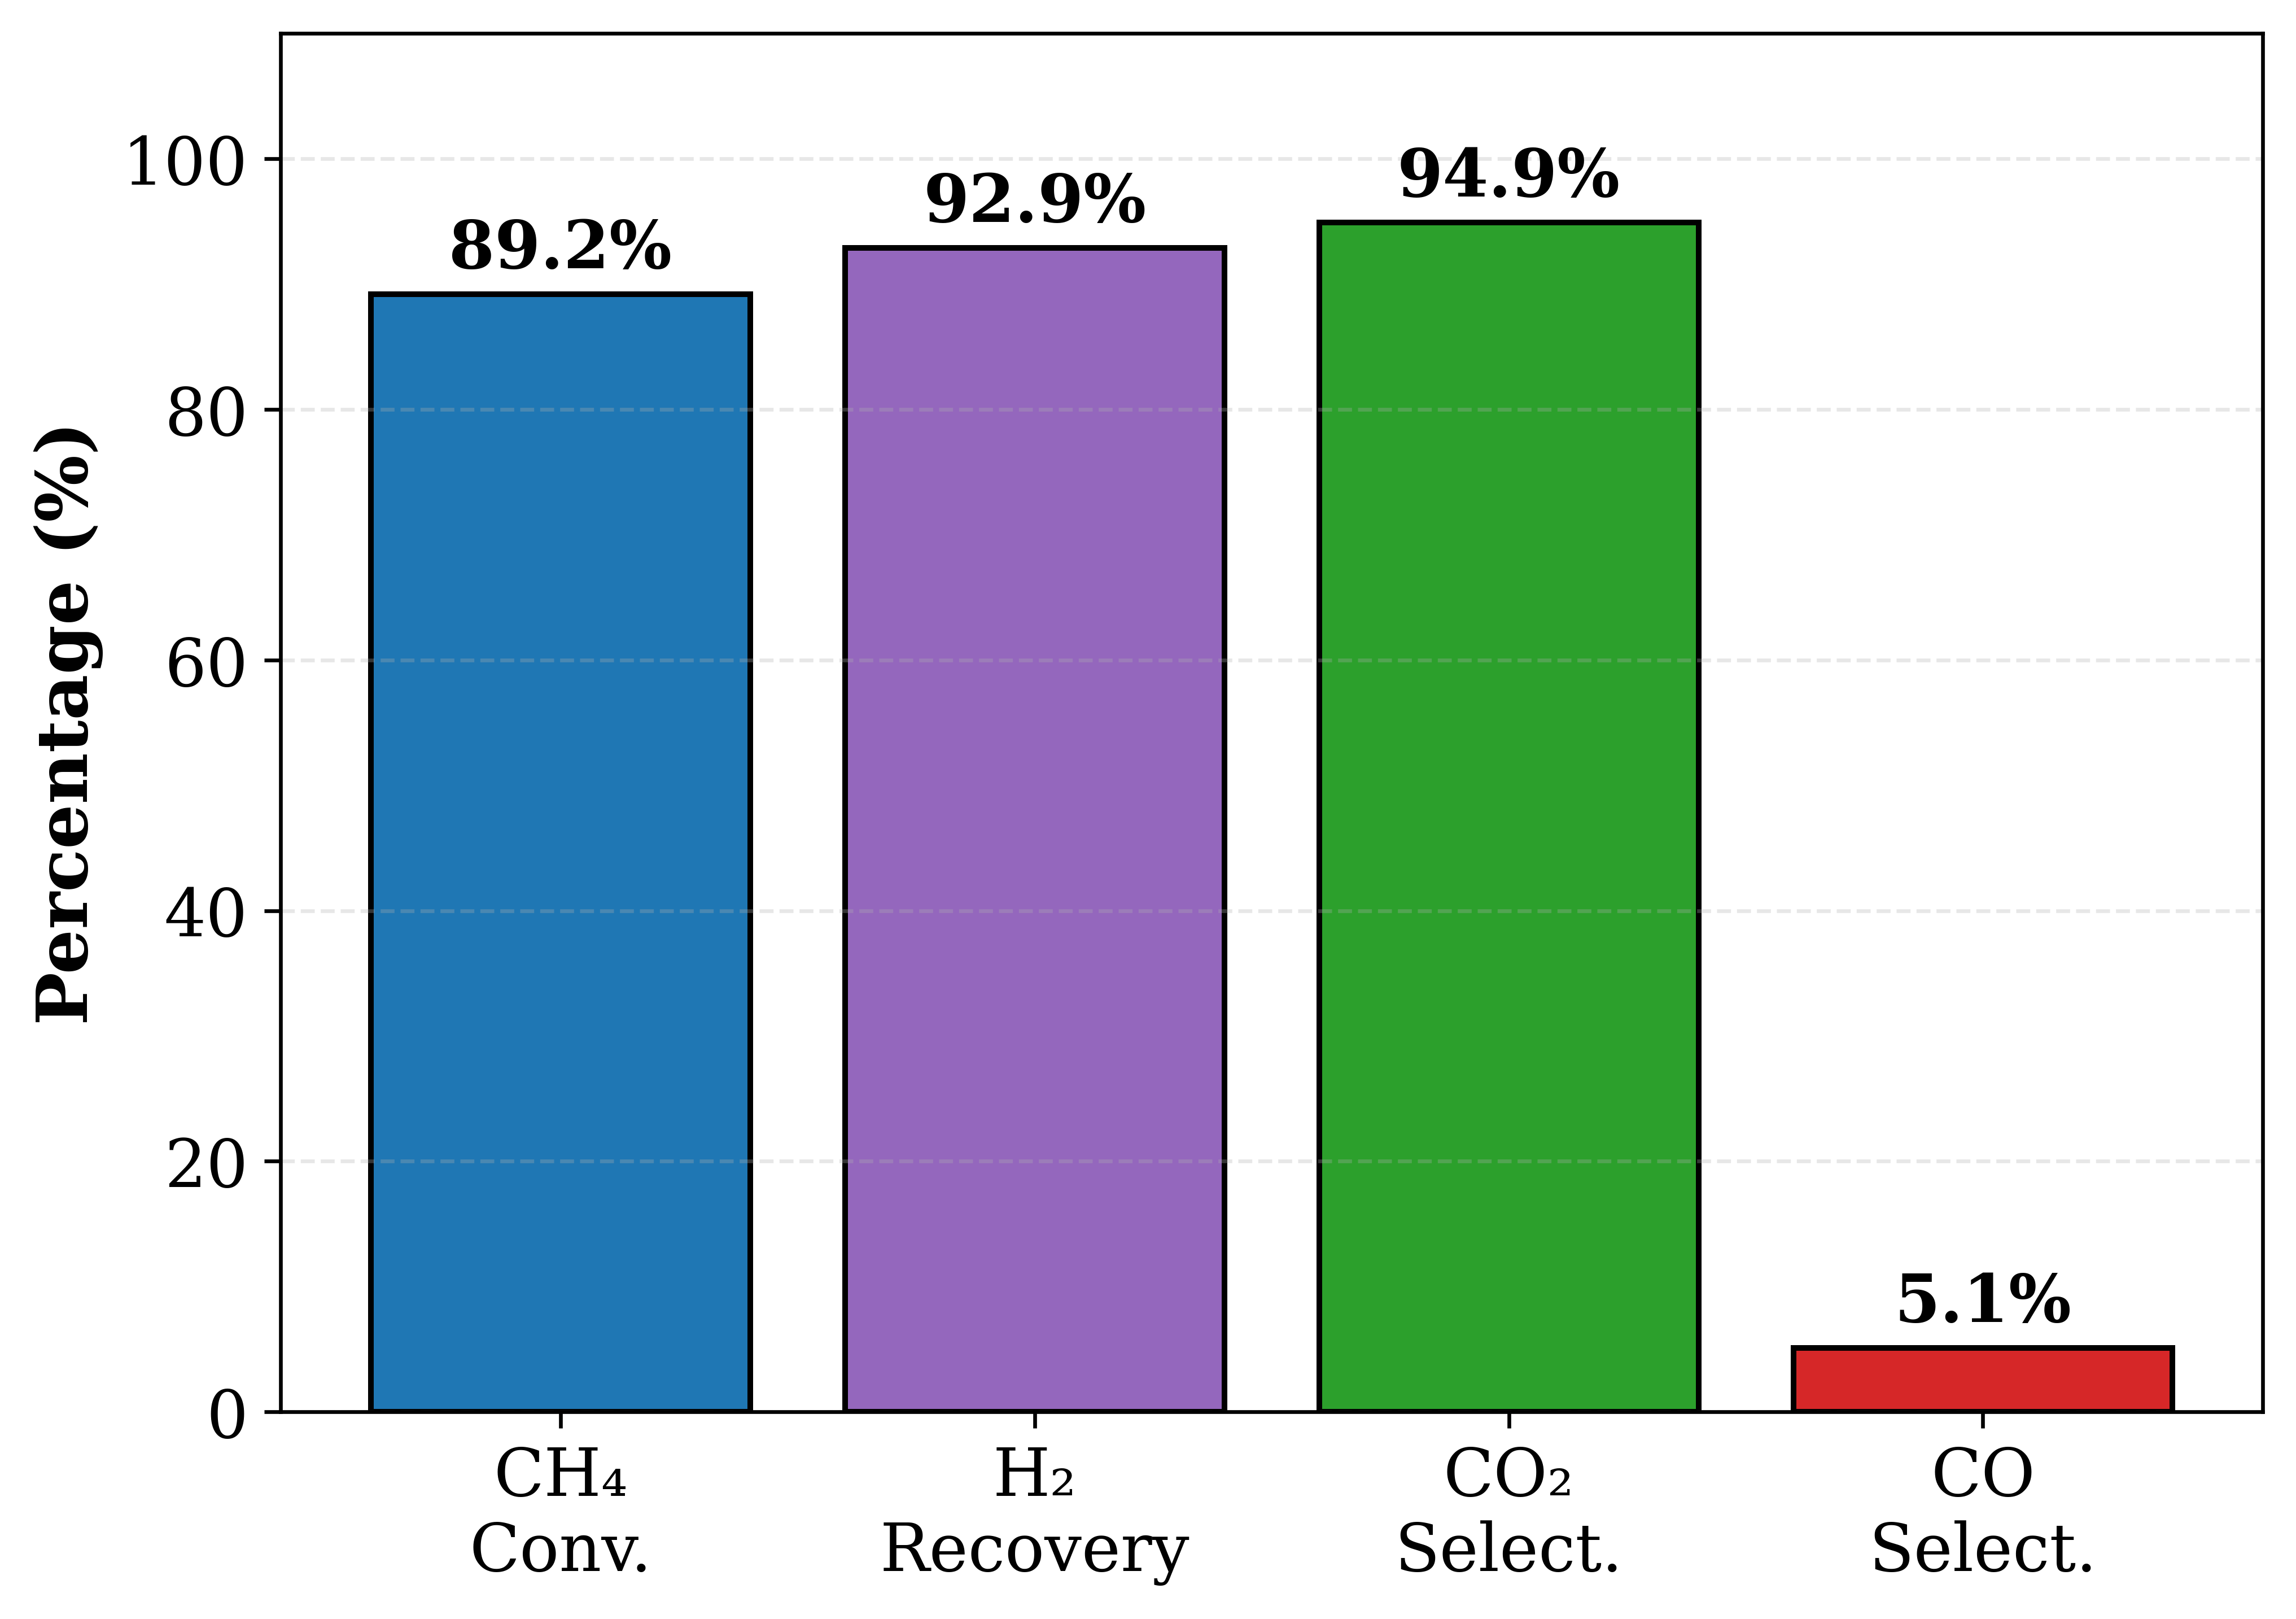

In [24]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Standalone figure: Reactor Performance Summary
Reads results from simulation_results_optimized.csv
"""
import pandas as pd
import matplotlib.pyplot as plt

# Load results
results = pd.read_csv('simulation_results_optimized.csv')
outlet = results.iloc[-1]

# Calculate metrics
S_CO2 = outlet['y_CO2'] / (outlet['y_CO'] + outlet['y_CO2']) * 100
S_CO = outlet['y_CO'] / (outlet['y_CO'] + outlet['y_CO2']) * 100

F_H2_perm_final = outlet['F_H2_perm']
F_H2_retentate = outlet['y_H2'] * outlet['F_total']
H2_recovery = F_H2_perm_final / (F_H2_perm_final + F_H2_retentate) * 100

# Print values for verification
print("=" * 50)
print("REACTOR PERFORMANCE SUMMARY")
print("=" * 50)
print(f"CH₄ Conversion:    {outlet['X_CH4']*100:.1f}%")
print(f"H₂ Recovery:       {H2_recovery:.1f}%")
print(f"CO₂ Selectivity:   {S_CO2:.1f}%")
print(f"CO Selectivity:    {S_CO:.1f}%")
print("=" * 50)

# Create figure
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 14
plt.rcParams['figure.dpi'] = 600

fig, ax = plt.subplots(figsize=(7, 5))

metrics = ['CH₄\nConv.', 'H₂\nRecovery', 'CO₂\nSelect.', 'CO\nSelect.']
values = [outlet['X_CH4'] * 100, H2_recovery, S_CO2, S_CO]
colors_bar = ['#1f77b4', '#9467bd', '#2ca02c', '#d62728']

bars = ax.bar(metrics, values, color=colors_bar, edgecolor='black', linewidth=1.2)

for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            f'{val:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=14)

ax.set_ylabel('Percentage (%)', fontweight='bold', fontsize=15)
#ax.set_title('Reactor Performance Summary\n(Pd-Ag Membrane Reactor, T = 550 °C)',
#             fontsize=12, fontweight='bold')
ax.set_ylim(0, 110)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')

plt.tight_layout()
plt.savefig('Figure1_Performance_Summary.png', dpi=600, bbox_inches='tight')
print("\n✓ Figure saved: Figure1_Performance_Summary.png")
plt.show()

EQUILIBRIUM CONSTANTS AT 550°C (823.15 K)
  K_eq,SMR = 8.3740e-02 bar²
  log10(K_eq,SMR) = -1.08
  K_eq,WGS = 3.7041
  log10(K_eq,WGS) = 0.57

✓ Figure saved: Figure2_Equilibrium_Constants.png


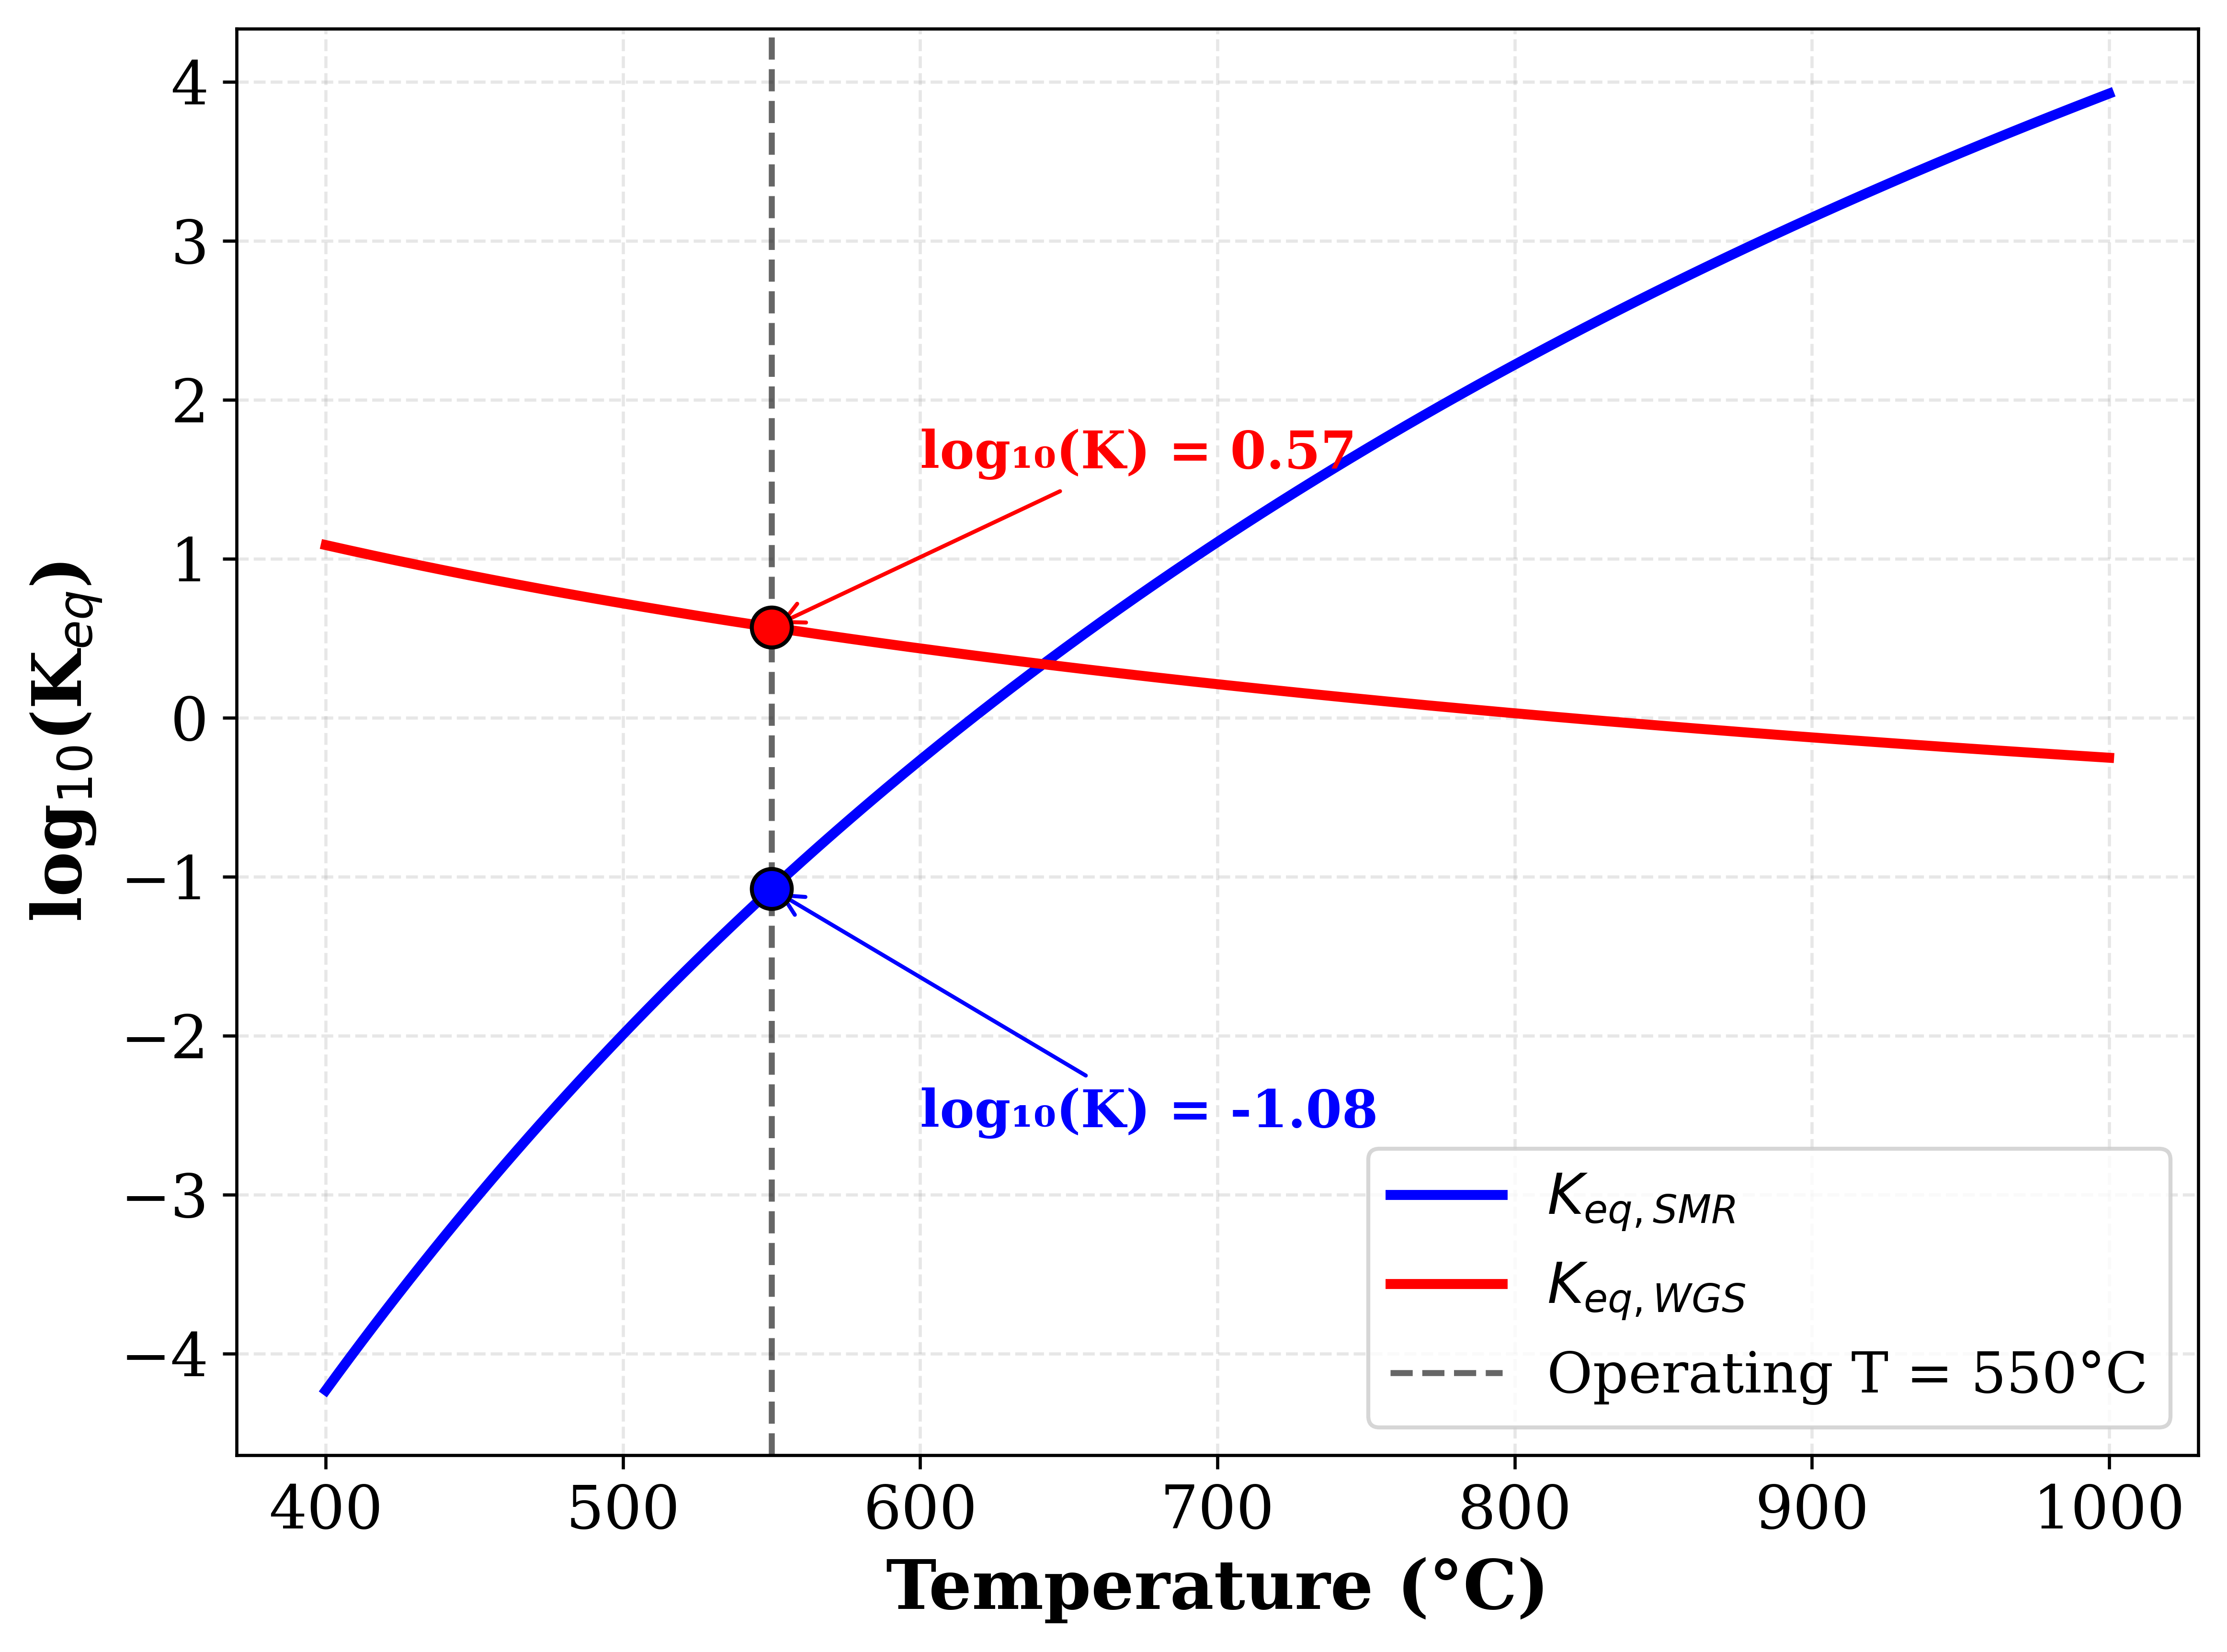

In [23]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Standalone figure: Equilibrium Constants vs Temperature (400-1000°C)
"""
import numpy as np
import matplotlib.pyplot as plt


# ============================================================================
# EQUILIBRIUM CONSTANTS FUNCTIONS
# ============================================================================
class XuFromentKinetics:
    """Xu & Froment (1989) equilibrium constants"""

    @staticmethod
    def Keq_SMR(T: float) -> float:
        """Equilibrium constant for SMR (bar²)"""
        return 1.198e13 * np.exp(-26830.0 / T)

    @staticmethod
    def Keq_WGS(T: float) -> float:
        """Equilibrium constant for WGS (dimensionless)"""
        return 1.767e-2 * np.exp(4400.0 / T)


# ============================================================================
# CREATE FIGURE
# ============================================================================
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 15
plt.rcParams['figure.dpi'] = 600

fig, ax = plt.subplots(figsize=(8, 6))

# Temperature range: 400 to 1000 °C  ← CHANGED
T_range = np.linspace(400, 1000, 300) + 273.15
Keq_SMR = [XuFromentKinetics.Keq_SMR(T) for T in T_range]
Keq_WGS = [XuFromentKinetics.Keq_WGS(T) for T in T_range]

# Plot equilibrium constants
ax.plot(T_range - 273.15, np.log10(Keq_SMR), 'b-', lw=2.5,
        label=r'$K_{eq,SMR}$')
ax.plot(T_range - 273.15, np.log10(Keq_WGS), 'r-', lw=2.5,
        label=r'$K_{eq,WGS}$')

# Operating point (550 °C)
T_op_C = 550.0
T_op_K = T_op_C + 273.15
Keq_SMR_op = XuFromentKinetics.Keq_SMR(T_op_K)
Keq_WGS_op = XuFromentKinetics.Keq_WGS(T_op_K)

# Vertical line at operating temperature
ax.axvline(x=T_op_C, color='k', linestyle='--', alpha=0.6,
           label=f'Operating T = {T_op_C:.0f}°C')

# Mark the operating points with markers
ax.plot(T_op_C, np.log10(Keq_SMR_op), 'bo', markersize=10,
        markeredgecolor='black', markeredgewidth=1, zorder=5)
ax.plot(T_op_C, np.log10(Keq_WGS_op), 'ro', markersize=10,
        markeredgecolor='black', markeredgewidth=1, zorder=5)

# Annotate the values at the operating point
ax.annotate(f'log₁₀(K) = {np.log10(Keq_SMR_op):.2f}',
            xy=(T_op_C, np.log10(Keq_SMR_op)),
            xytext=(T_op_C + 50, np.log10(Keq_SMR_op) - 1.5),
            fontsize=13, color='blue', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='blue', lw=1))

ax.annotate(f'log₁₀(K) = {np.log10(Keq_WGS_op):.2f}',
            xy=(T_op_C, np.log10(Keq_WGS_op)),
            xytext=(T_op_C + 50, np.log10(Keq_WGS_op) + 1.0),
            fontsize=13, color='red', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='red', lw=1))

# Labels
ax.set_xlabel('Temperature (°C)', fontweight='bold', fontsize=17)
ax.set_ylabel(r'log$_{10}$(K$_{eq}$)', fontweight='bold', fontsize=17)
#ax.set_title('Equilibrium Constants as Functions of Temperature',
#             fontsize=15, fontweight='bold')
ax.legend(loc='best', fontsize=14)
ax.grid(True, alpha=0.3, linestyle='--')



# Print verification values
print("=" * 60)
print("EQUILIBRIUM CONSTANTS AT 550°C (823.15 K)")
print("=" * 60)
print(f"  K_eq,SMR = {Keq_SMR_op:.4e} bar²")
print(f"  log10(K_eq,SMR) = {np.log10(Keq_SMR_op):.2f}")
print(f"  K_eq,WGS = {Keq_WGS_op:.4f}")
print(f"  log10(K_eq,WGS) = {np.log10(Keq_WGS_op):.2f}")
print("=" * 60)

plt.tight_layout()
plt.savefig('Figure2_Equilibrium_Constants.png', dpi=600, bbox_inches='tight')
print("\n✓ Figure saved: Figure2_Equilibrium_Constants.png")
plt.show()